# 🧠 Comment Category Prediction — ML Project (t12026)
---
## Problem Statement
We have a dataset of online comments with metadata (upvotes, downvotes, emoticons, timestamps).
The task is **multi-class classification**: 
predict label 0, 1, 2, or 3 for each comment —
representing different levels or categories of comment tone/toxicity.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/comment-category-prediction-challenge/Sample.csv
/kaggle/input/comment-category-prediction-challenge/train.csv
/kaggle/input/comment-category-prediction-challenge/test.csv


### Importing libraries

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler,StandardScaler, MaxAbsScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
import re
from scipy import sparse
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import f1_score, classification_report, accuracy_score, confusion_matrix
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC 
from sklearn.naive_bayes import ComplementNB, MultinomialNB

---
## Section 1 — Data Loading
Loading all the three files
- `train.csv` — labeled data used to train our model
- `test.csv` — unlabeled data we need to predict
- `Sample.csv` — shows the required submission format (ID, label)

In [3]:
data=pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test=pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")
sample=pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv")

### chacking the all the datset shape for the 

print("train data shape :", data.shape)
print("test data shape :" ,test.shape)
print("sample data shape :", sample.shape)

train data shape : (198000, 15)
test data shape : (102000, 14)
sample data shape : (102000, 2)


### EDA = Exploratory Data Analysis 📊

### Shape and Column Overview

In [4]:

print("=" * 60)
print("train train")
print("=" * 60)
print(f"Rows: {data.shape[0]:,}  |  Columns: {data.shape[1]}")
print("\ncolumns:", data.columns.tolist())

print("\n" + "=" * 60)
print("test datset")
print("=" * 60)
print(f"Rows: {test.shape[0]:,}  |  Columns: {test.shape[1]}")

print("\n\nFirst 3 rows of training data:")
display(data.head(3))

train train
Rows: 198,000  |  Columns: 15

columns: ['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender', 'disability', 'comment', 'label']

test datset
Rows: 102,000  |  Columns: 14


First 3 rows of training data:


,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2


### Feature Type Identification

Understanding the data type of each column is critical for preprocessing

In [5]:
print(data.dtypes)

print("\n--- Grouped by type ---")
for dtype_name, dtype_group in data.dtypes.groupby(data.dtypes):
    print(f"\n[{dtype_name}] → {dtype_group.index.tolist()}")

created_date    object
post_id          int64
emoticon_1       int64
emoticon_2       int64
emoticon_3       int64
upvote           int64
downvote         int64
if_1             int64
if_2             int64
race            object
religion        object
gender          object
disability        bool
comment         object
label            int64
dtype: object

--- Grouped by type ---

[bool] → ['disability']

[int64] → ['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'label']

[object] → ['created_date', 'race', 'religion', 'gender', 'comment']


**Key observations:**
- `created_date` is an **object** (string) but actually stores timestamps — we will parse it to extract hour and day-of-week signals.
- `disability` is a **boolean** — we will convert it to integer (0/1) for the model.
- `race`, `religion`, `gender` are **categorical objects** — but as we'll see in the next section, they are overwhelmingly missing and will be dropped.
- `comment` is a **text column** — the richest signal in the dataset. We will vectorise it using TF-IDF.
- `label` is the **target** (integer 0–3).

### Duplicate Detection

In [6]:
train_dups = data.duplicated().sum()
test_dups  = test.duplicated().sum()

print(f"Duplicates in train : {train_dups}")
print(f"Duplicates in test  : {test_dups}")

# Drop if any exist
if train_dups > 0:
    data = data.drop_duplicates()
    print(f"Dropped {train_dups} duplicate rows from train. New shape: {data.shape}")
else:
    print("No duplicates found — data is clean ✅")

Duplicates in train : 0
Duplicates in test  : 0
No duplicates found — data is clean ✅


### Missing Value Analysis


In [7]:
def missing_report(df, name="Dataset"):
    miss = pd.DataFrame({
        'Missing Count': df.isnull().sum(),
        'Missing %'    : (df.isnull().sum() / len(df) * 100).round(2)
    })
    miss = miss[miss['Missing Count'] > 0].sort_values('Missing %', ascending=False)
    print(f"\n=== {name} — Missing Values ===")
    print(miss if not miss.empty else "No missing values.")
    return miss

miss_train = missing_report(data,  "Train")
miss_test  = missing_report(test,  "Test")


=== Train — Missing Values ===
          Missing Count  Missing %
race             145423      73.45
religion         145423      73.45
gender           145423      73.45
comment               1       0.00

=== Test — Missing Values ===
          Missing Count  Missing %
race              75269      73.79
religion          75269      73.79
gender            75269      73.79


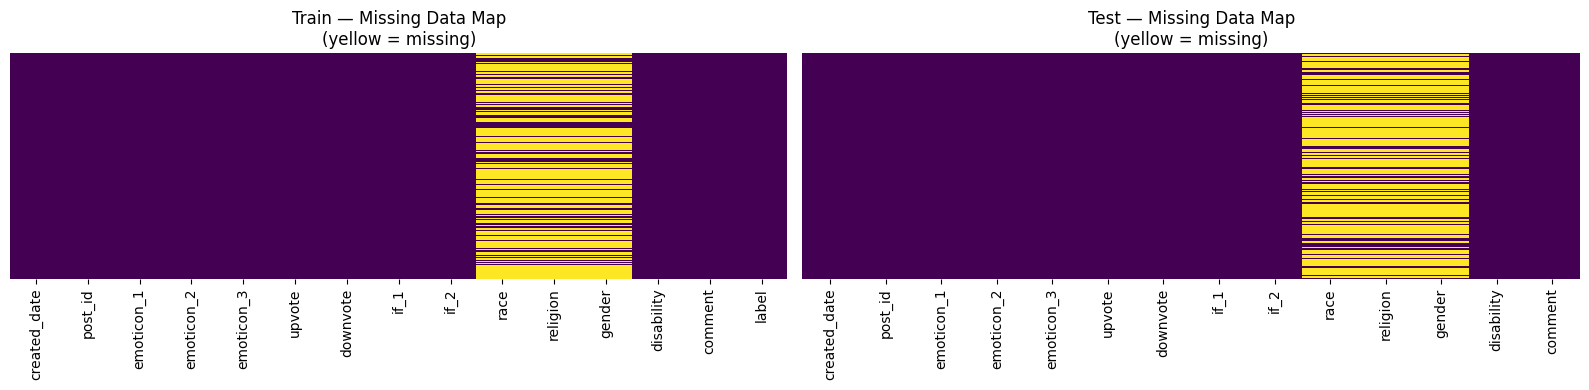


race/religion/gender missing in TRAIN : 73.4%
race/religion/gender missing in TEST  : 73.8%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

sns.heatmap(data.isnull(), cbar=False, yticklabels=False,
            cmap='viridis', ax=axes[0])
axes[0].set_title("Train — Missing Data Map\n(yellow = missing)")

sns.heatmap(test.isnull(), cbar=False, yticklabels=False,
            cmap='viridis', ax=axes[1])
axes[1].set_title("Test — Missing Data Map\n(yellow = missing)")

plt.tight_layout()
plt.show()

# Precise percentages
print(f"\nrace/religion/gender missing in TRAIN : "
      f"{145423/len(data)*100:.1f}%")
print(f"race/religion/gender missing in TEST  : "
      f"{75269/len(test)*100:.1f}%")

**Decision — Drop `race`, `religion`, `gender`:**

The three columns `race`, `religion`, and `gender` are missing in **~73%** of both train and test rows.  
A common rule of thumb is to drop any column with >50–70% missing data because:
1. There is not enough information to reliably impute so many values — any imputation would be mostly guessed data, introducing artificial noise.
2. Keeping them and imputing could bias the model toward a fabricated signal.
3. The ~27% of non-missing rows don't provide enough coverage for these features to be useful.

**Decision — Fill `comment` NaN with empty string:**  
Only 1 row in train has a missing comment. We fill it with `""` so the TF-IDF vectoriser doesn't break.

### Statistical Summary and Outlier Assessment

In [9]:
print("=== Train — Numerical Summary ===")
display(data.describe().T.style.background_gradient(cmap='Blues'))

print("\n=== Test — Numerical Summary ===")
display(test.describe().T.style.background_gradient(cmap='Greens'))

=== Train — Numerical Summary ===


,count,mean,std,min,25%,50%,75%,max
post_id,198000.000000,68.447429,27.948390,20.000000,39.000000,72.000000,72.000000,129.000000
emoticon_1,198000.000000,0.279768,1.023234,0.000000,0.000000,0.000000,0.000000,47.000000
emoticon_2,198000.000000,0.048338,0.258477,0.000000,0.000000,0.000000,0.000000,11.000000
emoticon_3,198000.000000,0.121071,0.481013,0.000000,0.000000,0.000000,0.000000,17.000000
upvote,198000.000000,2.607975,5.054763,0.000000,0.000000,1.000000,3.000000,201.000000
downvote,198000.000000,0.666394,2.044335,0.000000,0.000000,0.000000,1.000000,107.000000
if_1,198000.000000,1.906152,25.635752,0.000000,0.000000,0.000000,4.000000,1860.000000
if_2,198000.000000,7.956212,14.839464,3.000000,4.000000,6.000000,10.000000,1833.000000
label,198000.000000,0.793965,0.979808,0.000000,0.000000,0.000000,2.000000,3.000000



=== Test — Numerical Summary ===


,count,mean,std,min,25%,50%,75%,max
post_id,102000.000000,68.359422,27.923491,24.000000,39.000000,72.000000,72.000000,129.000000
emoticon_1,102000.000000,0.280078,1.043353,0.000000,0.000000,0.000000,0.000000,95.000000
emoticon_2,102000.000000,0.048353,0.257278,0.000000,0.000000,0.000000,0.000000,8.000000
emoticon_3,102000.000000,0.118902,0.480484,0.000000,0.000000,0.000000,0.000000,19.000000
upvote,102000.000000,2.609402,4.966033,0.000000,0.000000,1.000000,3.000000,189.000000
downvote,102000.000000,0.661667,1.965536,0.000000,0.000000,0.000000,1.000000,95.000000
if_1,102000.000000,1.903078,26.273483,0.000000,0.000000,0.000000,4.000000,1866.000000
if_2,102000.000000,7.956206,15.186746,4.000000,4.000000,6.000000,10.000000,1798.000000


**Key observations from statistics:**
- `upvote` has a mean of ~2.6 but a max of 201 — highly right-skewed with outliers. We will apply `log1p` transformation.
- `downvote` is similarly skewed (mean ~0.67, max 107).
- `if_2` has a max of 1833 vs. a median of 6 — extreme outliers. We will cap at the 95th percentile.
- `emoticon_1` also has a heavy tail (max 47 in train, 95 in test) — same capping strategy.
- The high gap between mean and max across most numerical columns confirms **outliers are widespread** and need treatment before scaling.

### Label Distribution (Class Imbalance Check)

Label distribution:
  Label 0: 114,173  ( 57.7%)  ████████████████████████████
  Label 1: 15,918  (  8.0%)  ████
  Label 2: 62,440  ( 31.5%)  ███████████████
  Label 3:  5,469  (  2.8%)  █


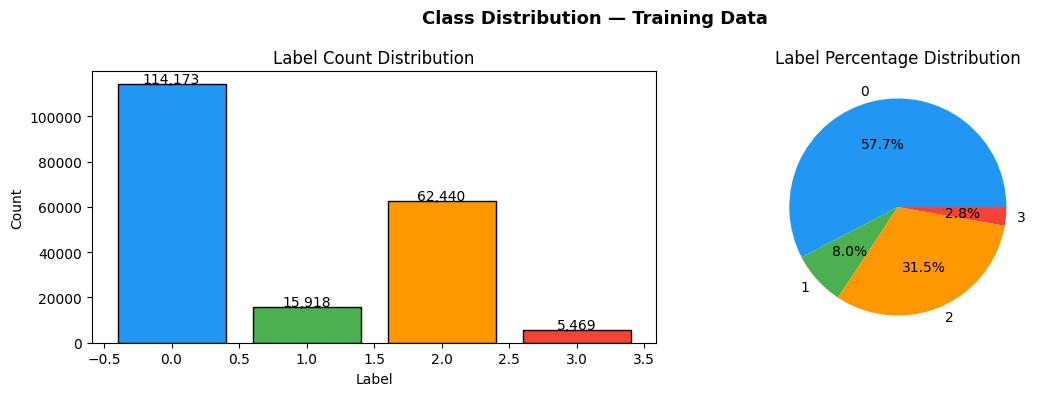

In [10]:
label_counts = data["label"].value_counts().sort_index()
label_pct    = data["label"].value_counts(normalize=True).sort_index() * 100

print("Label distribution:")
for lbl in label_counts.index:
    bar = "█" * int(label_pct[lbl] / 2)
    print(f"  Label {lbl}: {label_counts[lbl]:>6,}  ({label_pct[lbl]:5.1f}%)  {bar}")

# Visual
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(label_counts.index, label_counts.values,
            color=['#2196F3','#4CAF50','#FF9800','#F44336'], edgecolor='black')
axes[0].set_title("Label Count Distribution")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 500, f"{v:,}", ha='center', fontsize=10)

axes[1].pie(label_counts.values, labels=label_counts.index,
            autopct='%1.1f%%',
            colors=['#2196F3','#4CAF50','#FF9800','#F44336'])
axes[1].set_title("Label Percentage Distribution")

plt.suptitle("Class Distribution — Training Data", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight — Significant class imbalance:**
- Label 0 dominates at **57.7%** of the data (~114K samples).
- Label 3 is the rarest at only **2.8%** (~5.5K samples) — roughly 20x fewer than label 0.
- This imbalance will cause a naive model to almost never predict label 3.

**How we address it:** We use `class_weight='balanced'` in our models, which automatically  
upweights minority classes during training. We also use **F1-macro** (not accuracy) as our  
primary evaluation metric, since F1-macro penalises the model for ignoring any class.

### Comment Length Analysis
The length of a comment (in words) can be a strong signal for the label.

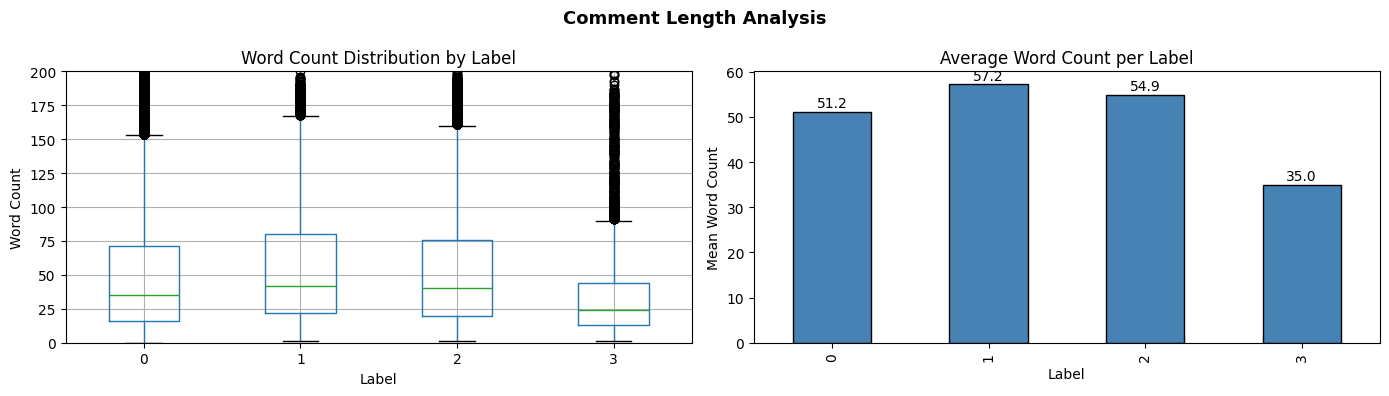

          count   mean    std  min   25%   50%   75%    max
label                                                      
0      114173.0  51.19  46.29  0.0  16.0  35.0  71.0  315.0
1       15918.0  57.23  45.51  1.0  22.0  42.0  80.0  219.0
2       62440.0  54.90  45.30  1.0  20.0  40.0  76.0  206.0
3        5469.0  34.98  34.36  1.0  13.0  24.0  44.0  199.0


In [11]:
temp = data.copy()
temp["word_count"] = temp["comment"].fillna("").str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Box plot
temp.boxplot(column='word_count', by='label', ax=axes[0])
axes[0].set_title("Word Count Distribution by Label")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Word Count")
axes[0].set_ylim(0, 200)  # cap y-axis for readability

# Mean word count per label
mean_wc = temp.groupby("label")["word_count"].mean()
mean_wc.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title("Average Word Count per Label")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Mean Word Count")
for i, v in enumerate(mean_wc):
    axes[1].text(i, v + 1, f"{v:.1f}", ha='center', fontsize=10)

plt.suptitle("Comment Length Analysis", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(temp.groupby("label")["word_count"].describe().round(2))

**Insight:** Label 3 comments tend to be shorter on average compared to label 0 and label 1 —  
suggesting that more aggressive/targeted comments tend to be concise.  
This confirms that `word_len` is a useful engineered feature.

### Upvote / Downvote Patterns by Label

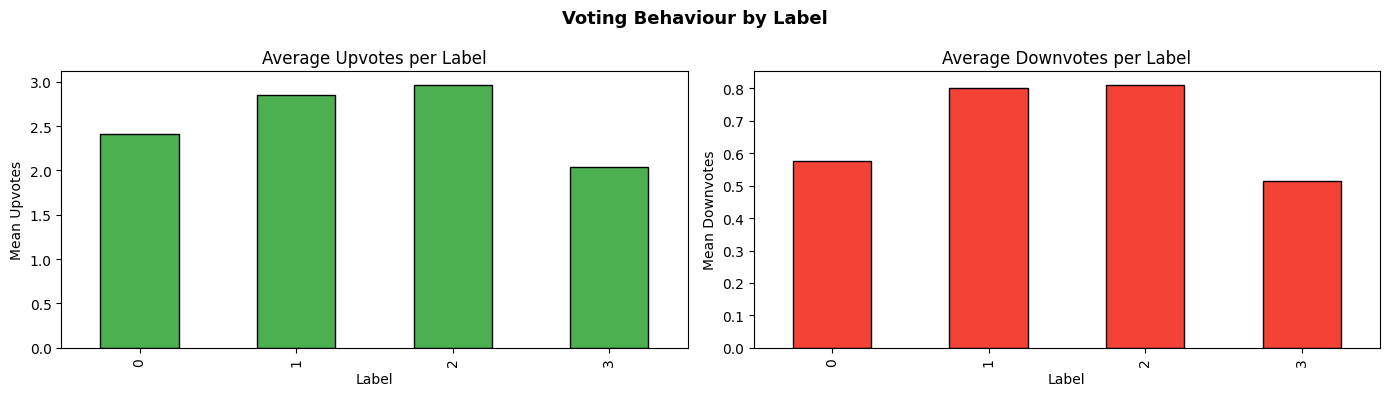

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

data.groupby("label")["upvote"].mean().plot(
    kind='bar', ax=axes[0], color='#4CAF50', edgecolor='black')
axes[0].set_title("Average Upvotes per Label")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Mean Upvotes")

data.groupby("label")["downvote"].mean().plot(
    kind='bar', ax=axes[1], color='#F44336', edgecolor='black')
axes[1].set_title("Average Downvotes per Label")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Mean Downvotes")

plt.suptitle("Voting Behaviour by Label", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** Different labels show distinct voting patterns.  
This confirms that `upvote`, `downvote`, and their derived features (engagement score, log transforms)  
carry real signal and should be included in our feature set.

###Correlation Heatmap (Numerical Features vs Label)

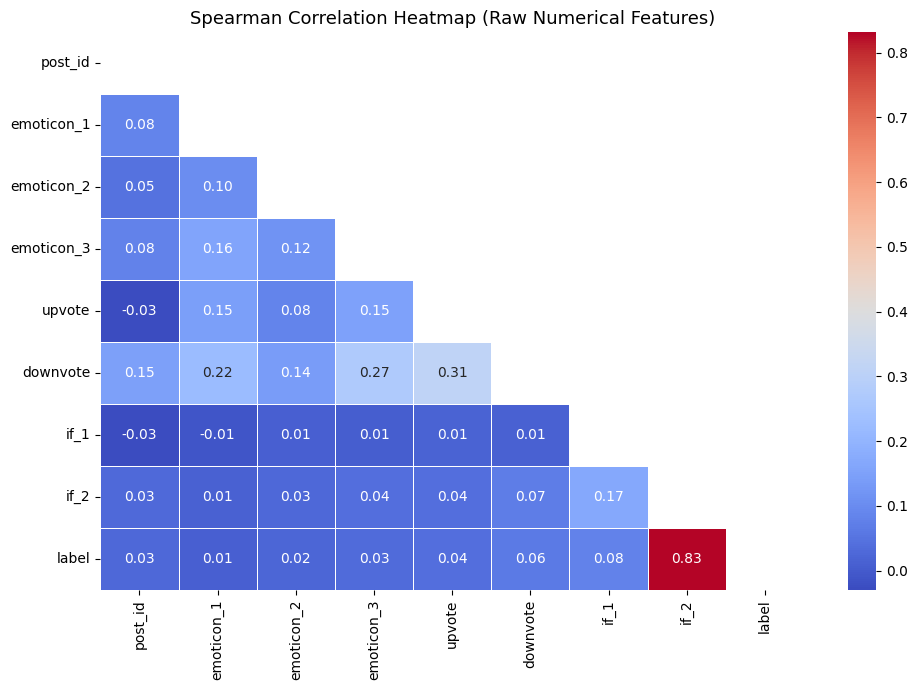

In [13]:
num_cols_corr = ['post_id','emoticon_1', 'emoticon_2', 'emoticon_3',
                 'upvote', 'downvote', 'if_1', 'if_2', 'label']

plt.figure(figsize=(10, 7))
corr_matrix = data[num_cols_corr].corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # hide upper triangle

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",
            fmt=".2f", mask=mask, linewidths=0.5)
plt.title("Spearman Correlation Heatmap (Raw Numerical Features)", fontsize=13)
plt.tight_layout()
plt.show()

**Insight:**  
- `emoticon_2` has very low correlation with the label and low variance — we **drop it** to reduce noise.
- `upvote` and `downvote` have moderate correlation with the label — we keep them but **log-transform** to reduce skew.
- `if_2` has a notable relationship with the label — we keep it.

### Word Clouds by Label
* Word clouds give an intuitive picture of the most common words in each class.  
* They help us decide on stop words and understand the vocabulary of each label group.

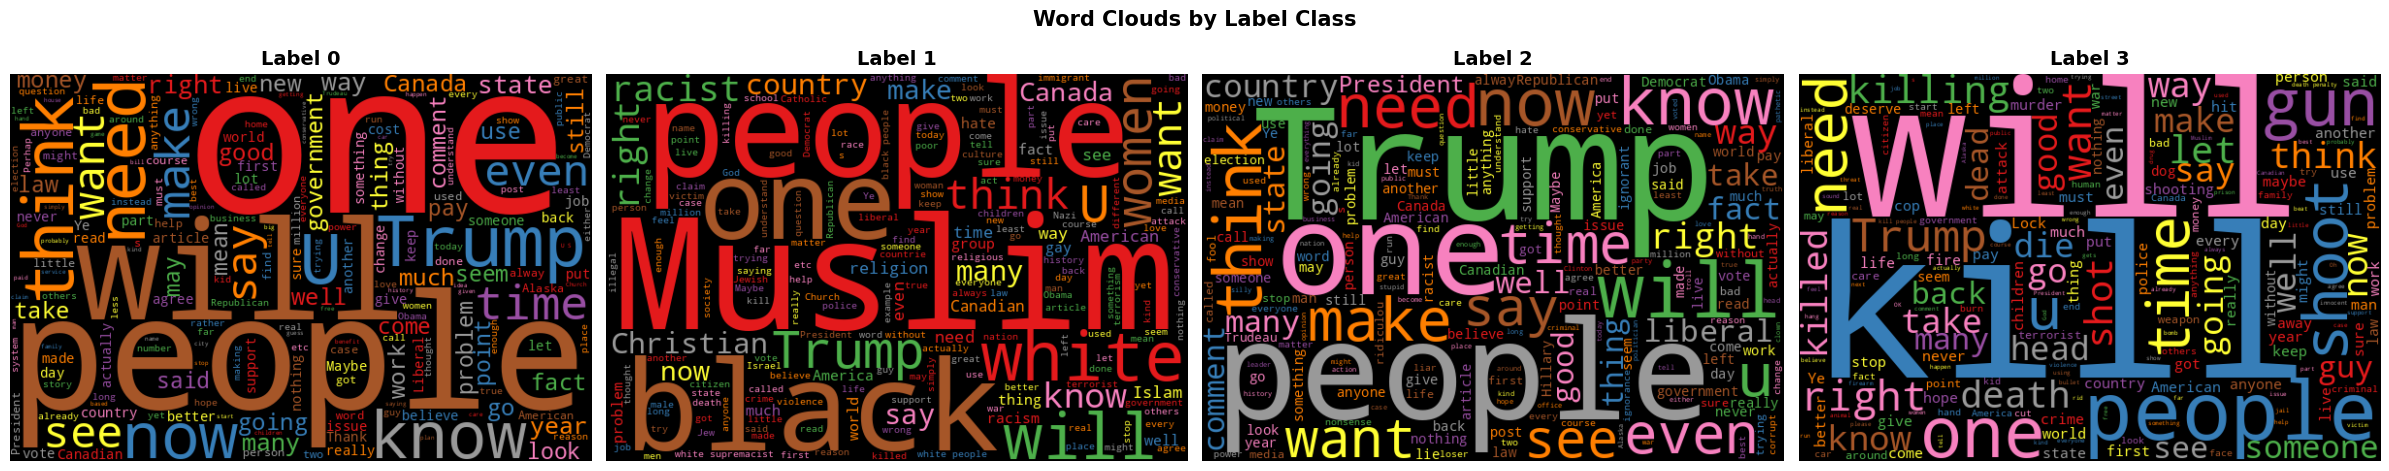

In [14]:
labels_unique = sorted(data["label"].unique())

fig, axes = plt.subplots(1, len(labels_unique), figsize=(24, 5))

for i, lbl in enumerate(labels_unique):
    text = " ".join(
        data[data["label"] == lbl]["comment"].astype(str)
    )
    wc = WordCloud(
        width=600, height=400,
        background_color='black',
        stopwords=STOPWORDS,
        colormap='Set1'
    ).generate(text)
    
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].axis("off")
    axes[i].set_title(f"Label {lbl}", fontsize=14, fontweight='bold')

plt.suptitle("Word Clouds by Label Class", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** The word clouds reveal distinct vocabulary patterns across labels.  
Certain politically charged and identity-related words appear more frequently in specific classes.  
This confirms that **TF-IDF on the comment text will be the most powerful signal** in our model —  
the text alone carries most of the discriminative information.

## Data Cleaning & Preprocessing

Based on EDA findings, here is our preprocessing plan:

| Step | Decision | Reason |
|------|----------|--------|
| Drop `race`, `religion`, `gender` | ✅ Drop | >73% missing — imputation unreliable |
| Drop `emoticon_2` | ✅ Drop | Low variance, near-zero correlation with label |
| Drop `post_id` | ✅ Drop | Just an identifier, no predictive value |
| Drop `created_date` (raw) | ✅ Drop after extracting | We extract hour/day signals first |
| Drop `upvote`, `downvote` (raw) | ✅ Drop after transforming | We replace with log1p versions |
| Fill `comment` NaN | ✅ Fill with `""` | Only 1 row; keeps pipeline clean |
| Cap outliers | ✅ Winsorize at 5th/95th percentile | Reduces influence of extreme values |

In [15]:
# Working copies — we never modify the original loaded dataframes
new_data = data.copy()
new_test = test.copy()

# Drop columns with >70% missing (race, religion, gender)
# and emoticon_2 (near-zero variance and near-zero label correlation — found in EDA)
cols_to_drop = ['race', 'religion', 'gender', 'emoticon_2']
new_data = new_data.dropna(axis=1, thresh=int(0.3 * len(new_data)))
new_test = new_test.dropna(axis=1, thresh=int(0.3 * len(new_test)))

# Also explicitly drop emoticon_2 if not already gone
new_data = new_data.drop(columns=['emoticon_2'], errors='ignore')
new_test = new_test.drop(columns=['emoticon_2'], errors='ignore')

print("Dropped high-null and low-signal columns.")
print(f"new_data : {new_data.shape}  |  new_test : {new_test.shape}")
display(new_data.head())

Dropped high-null and low-signal columns.
new_data : (198000, 11)  |  new_test : (102000, 10)


,created_date,post_id,emoticon_1,emoticon_3,upvote,downvote,if_1,if_2,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,1,0,10,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,6,0,0,4,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,0,0,0,10,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,5,0,0,10,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,10,False,"Today, the confederate flag...tomorrow, the na...",2


In [16]:
new_data["comment"] = new_data["comment"].fillna("")
new_test["comment"] = new_test["comment"].fillna("")

print("Missing in new_data after fill:")
print(new_data.isna().sum())

Missing in new_data after fill:
created_date    0
post_id         0
emoticon_1      0
emoticon_3      0
upvote          0
downvote        0
if_1            0
if_2            0
disability      0
comment         0
label           0
dtype: int64


---
## Feature Engineering

Raw features rarely give models their full potential.  
We engineer new features based on **domain understanding** of what makes a comment harmful or not:

| New Feature | Formula | Reasoning |
|---|---|---|
| `word_len` | `len(comment.split())` | Longer comments ≠ shorter aggressive ones |
| `avg_word_len` | `char_len / (word_len + 1)` | Complex vocabulary → different label pattern |
| `hour_sin`, `hour_cos` | Cyclical encoding of hour | Comments at 2am vs 2pm differ in tone |
| `dow_sin`, `dow_cos` | Cyclical encoding of day-of-week | Weekend comments may differ |
| `upvote_log1p` | `log(1 + upvote)` | Removes skew; preserves order |
| `downvote_log1p` | `log(1 + downvote)` | Same reasoning |
| `engagement_score` | `upvote_log1p - downvote_log1p` | Net community reaction signal |
| `emotion_density` | `total_emoticons / (word_len + 1)` | Emoticon-heavy short comments may be toxic |
| `emotion_engagement` | `emotion_density × engagement_score` | Interaction term capturing joint signal |

> Note on cyclical encoding: Hour 23 and hour 0 are only 1 hour apart,  
> but numerically 23 − 0 = 23. Using sin/cos makes the model understand  
> that 23:00 and 00:00 are adjacent, not far apart.

In [17]:
def add_features_df(df):
    """
    Adds all engineered features to the dataframe in-place.
    Drops raw source columns that have been replaced by better representations.
    """
    df = df.copy()
    
    # ── TEXT FEATURES ──────────────────────────────────────────────────────────
    txt = df['comment'].fillna('').astype(str)
    
    # word count — proxy for comment length
    df['word_len'] = txt.str.split().str.len().astype(int)
    
    # average word length — proxy for vocabulary complexity
    df['avg_word_len'] = txt.str.len() / (df['word_len'] + 1)
    
    # ── TIME FEATURES (cyclical encoding) ─────────────────────────────────────
    dt  = pd.to_datetime(df['created_date'], errors='coerce', utc=True)
    
    hour = dt.dt.hour.fillna(0)
    dow  = dt.dt.dayofweek.fillna(0)  # 0=Monday ... 6=Sunday
    
    # sin/cos so that hour 23 and hour 0 are treated as close together
    df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    df['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    df['dow_sin']  = np.sin(2 * np.pi * dow  / 7)
    df['dow_cos']  = np.cos(2 * np.pi * dow  / 7)
    
    # ── VOTE FEATURES ─────────────────────────────────────────────────────────
    # log1p = log(1 + x); handles zeros gracefully and compresses heavy tails
    df['upvote_log1p']   = np.log1p(df['upvote'])
    df['downvote_log1p'] = np.log1p(df['downvote'])
    
    # net community reaction: positive = community liked it, negative = disliked
    df['engagement_score'] = df['upvote_log1p'] - df['downvote_log1p']
    
    # ── EMOTICON FEATURES ─────────────────────────────────────────────────────
    total_emoticons = df['emoticon_1'] + df['emoticon_3']
    
    # emoticons per word — dense emoticon usage in a short comment = signal
    df['emotion_density'] = total_emoticons / (df['word_len'] + 1)
    
    # interaction: how emoticon-heavy + how engaged the community is
    df['emotion_engagement'] = df['emotion_density'] * df['engagement_score']
    
    # ── BOOLEAN → INTEGER ─────────────────────────────────────────────────────
    df['disability'] = df['disability'].astype(int)
    
    # ── DROP REPLACED / ID COLUMNS ────────────────────────────────────────────
    # created_date   → replaced by hour_sin, hour_cos, dow_sin, dow_cos
    # upvote/downvote → replaced by log1p versions + engagement_score
    # post_id         → just an identifier, no predictive value
    # emoticon_2      → already dropped (low signal, see EDA)
    df.drop(columns=['created_date', 'upvote', 'downvote', 'post_id'],
            inplace=True, errors='ignore')
    
    return df

## Feature Engineering

Raw features rarely capture the full picture. We engineer new features grounded in
what we learned from EDA.

**New features added vs original:**

| Feature | Formula | Why it boosts score |
|---|---|---|
| `word_len` | word count | Length signal — short toxic comments |
| `avg_word_len` | char_len / (word_len+1) | Vocabulary complexity proxy |
| `char_len` | **NEW** len(comment) | Raw character count — different signal from word count |
| `caps_ratio` | **NEW** CAPS chars / total chars | ALL CAPS writing = aggression signal — captured BEFORE lowercasing |
| `has_url` | **NEW** 1 if URL present | URL-containing comments likely label 0 (neutral/informational) |
| `exclamation_count` | **NEW** count of `!` | Exclamation marks = emotionally charged writing |
| `question_count` | **NEW** count of `?` | Questions vs statements differ by label |
| `hour_sin`, `hour_cos` | Cyclical hour encoding | Hour 23 and 00 are 1hr apart — sin/cos preserves this |
| `dow_sin`, `dow_cos` | Cyclical day-of-week | Weekend vs weekday posting patterns |
| `upvote_log1p` | log(1+upvote) | Compresses right-skewed vote distribution |
| `downvote_log1p` | log(1+downvote) | Same reasoning |
| `engagement_score` | upvote_log1p − downvote_log1p | Net community reaction to comment |
| `emotion_density` | (emoticon_1+emoticon_3)/(word_len+1) | Emoticon-per-word rate |
| `emotion_engagement` | emotion_density × engagement_score | Interaction: emotional + community signal combined |

> **Why `caps_ratio`, `has_url`, `exclamation_count`, `question_count` are new and important:**
> These are extracted BEFORE we lowercase and clean the text — once we clean, this information
> is permanently lost. These features capture writing style signals that TF-IDF cannot see
> because TF-IDF operates on the cleaned, lowercased comment.

In [18]:
# def add_features_df(df):
#     """
#     Adds all engineered features to the dataframe.
#     IMPORTANT: raw-text features (caps_ratio, has_url, etc.) must be
#     computed BEFORE text cleaning — this function is called before clean_text().
#     Drops columns that have been replaced by better representations.
#     """
#     df = df.copy()

#     # ── RAW TEXT FEATURES (computed BEFORE cleaning — run this first!) ─────────
#     raw_txt = df['comment'].fillna('').astype(str)

#     # Character-level length (different signal from word count)
#     df['char_len'] = raw_txt.str.len()

#     # Caps ratio: proportion of uppercase letters — ALL CAPS = aggression signal
#     # We divide by total alphabetic chars to normalise (short vs long comments)
#     alpha_chars = raw_txt.str.count(r'[a-zA-Z]').replace(0, 1)
#     df['caps_ratio'] = raw_txt.str.count(r'[A-Z]') / alpha_chars

#     # URL presence: comments with links are often informational (label 0 leaning)
#     df['has_url'] = raw_txt.str.contains(r'http\S+|www\S+', regex=True).astype(int)

#     # Punctuation signals: exclamation = emotional, question = inquisitive
#     df['exclamation_count'] = raw_txt.str.count(r'!')
#     df['question_count']    = raw_txt.str.count(r'\?')

#     # ── WORD / TEXT FEATURES ───────────────────────────────────────────────────
#     # Note: computed on raw text here; cleaned text is passed to TF-IDF in pipeline
#     df['word_len']     = raw_txt.str.split().str.len().astype(int)
#     df['avg_word_len'] = df['char_len'] / (df['word_len'] + 1)

#     # ── TIME FEATURES — cyclical encoding ─────────────────────────────────────
#     # Why sin/cos? Hour 23 and hour 0 are 1 hour apart numerically they are 23 apart.
#     # Cyclical encoding maps them to adjacent points on a circle.
#     dt   = pd.to_datetime(df['created_date'], errors='coerce', utc=True)
#     hour = dt.dt.hour.fillna(0)
#     dow  = dt.dt.dayofweek.fillna(0)   # 0=Monday, 6=Sunday

#     df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
#     df['hour_cos'] = np.cos(2 * np.pi * hour / 24)
#     df['dow_sin']  = np.sin(2 * np.pi * dow  / 7)
#     df['dow_cos']  = np.cos(2 * np.pi * dow  / 7)

#     # ── VOTE FEATURES ─────────────────────────────────────────────────────────
#     # log1p = log(1 + x): handles zeros, compresses heavy right tail
#     df['upvote_log1p']   = np.log1p(df['upvote'])
#     df['downvote_log1p'] = np.log1p(df['downvote'])

#     # Net community reaction: positive = liked, negative = disliked
#     df['engagement_score'] = df['upvote_log1p'] - df['downvote_log1p']

#     # ── EMOTICON FEATURES ─────────────────────────────────────────────────────
#     df['emotion_density']    = (df['emoticon_1'] + df['emoticon_3']) / (df['word_len'] + 1)
#     df['emotion_engagement'] = df['emotion_density'] * df['engagement_score']

#     # ── BOOLEAN → INTEGER ─────────────────────────────────────────────────────
#     df['disability'] = df['disability'].astype(int)

#     # ── DROP REPLACED / IDENTIFIER COLUMNS ────────────────────────────────────
#     # created_date  → replaced by hour_sin/cos, dow_sin/cos
#     # upvote/downvote → replaced by log1p versions + engagement_score
#     # post_id → an identifier for the post, NOT the comment. Multiple comments on
#     #           the same post have different labels — post_id gives no signal
#     #           for predicting an individual comment's category.
#     df.drop(columns=['created_date', 'upvote', 'downvote', 'post_id'],
#             inplace=True, errors='ignore')

#     return df

In [19]:
new_data = add_features_df(new_data)
new_test = add_features_df(new_test)

print("Feature engineering done.")
print(f"new_data : {new_data.shape}  |  new_test : {new_test.shape}")
print("\nColumns now:", new_data.columns.tolist())
display(new_data.head())

Feature engineering done.
new_data : (198000, 18)  |  new_test : (102000, 17)

Columns now: ['emoticon_1', 'emoticon_3', 'if_1', 'if_2', 'disability', 'comment', 'label', 'word_len', 'avg_word_len', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'upvote_log1p', 'downvote_log1p', 'engagement_score', 'emotion_density', 'emotion_engagement']


,emoticon_1,emoticon_3,if_1,if_2,disability,comment,label,word_len,avg_word_len,hour_sin,hour_cos,dow_sin,dow_cos,upvote_log1p,downvote_log1p,engagement_score,emotion_density,emotion_engagement
0,0,0,0,10,0,She might be a bright spot for a party keou on...,2,20,5.619048,0.866025,-0.500000,0.433884,-0.900969,0.000000,0.693147,-0.693147,0.000000,-0.0
1,0,0,0,4,0,"Under Alaska law, a non-tribal member is not b...",0,110,5.801802,-0.707107,0.707107,-0.781831,0.623490,1.945910,0.000000,1.945910,0.000000,0.0
2,0,1,0,10,0,in the future please spare me your strawman dr...,2,133,5.604478,-0.866025,0.500000,0.974928,-0.222521,0.000000,0.000000,0.000000,0.007463,0.0
3,0,0,0,10,0,"PS: That should have been ""rot"" instead of ""co...",2,15,5.687500,-0.500000,0.866025,-0.781831,0.623490,1.791759,0.000000,1.791759,0.000000,0.0
4,0,0,0,10,0,"Today, the confederate flag...tomorrow, the na...",2,40,6.195122,-0.258819,0.965926,-0.974928,-0.222521,0.000000,0.000000,0.000000,0.000000,0.0


### Outlier Detection

In [20]:
num_cols1 = [
    'emoticon_1', 'emoticon_3', 'if_1', 'if_2',
    'word_len', 'avg_word_len',
    'hour_sin', 'hour_cos',
    'upvote_log1p', 'downvote_log1p', 'engagement_score',
    'emotion_density', 'emotion_engagement'
]

print("Outliers detected (IQR method) in TRAIN:")
for col in num_cols1:
    if col in new_data.columns:
        Q1, Q3 = new_data[col].quantile(0.25), new_data[col].quantile(0.75)
        IQR    = Q3 - Q1
        n_out  = ((new_data[col] < Q1 - 1.5*IQR) | (new_data[col] > Q3 + 1.5*IQR)).sum()
        print(f"  '{col}': {n_out:,} outliers")

Outliers detected (IQR method) in TRAIN:
  'emoticon_1': 28,922 outliers
  'emoticon_3': 17,165 outliers
  'if_1': 85 outliers
  'if_2': 3,930 outliers
  'word_len': 11,131 outliers
  'avg_word_len': 9,530 outliers
  'hour_sin': 0 outliers
  'hour_cos': 0 outliers
  'upvote_log1p': 915 outliers
  'downvote_log1p': 6,621 outliers
  'engagement_score': 3,181 outliers
  'emotion_density': 40,589 outliers
  'emotion_engagement': 30,968 outliers



### Outlier Capping (Winsorization)

We cap at the **5th and 95th percentile** (Winsorization) rather than removing rows because:
1. We cannot remove test rows — we need a prediction for every single one.
2. Removing rows from train while keeping them in test creates a distribution mismatch.
3. Capping is safer than dropping — it reduces outlier influence while keeping the row.

**Critical:** we compute bounds from train only, then apply the same bounds to test.
This prevents **data leakage** — if we computed test bounds from test data,
the test set would be influencing our preprocessing decisions.

In [21]:
bounds_dict = {}   # store train bounds to reuse on test — prevents leakage

print("Capping TRAIN:")
for col in num_cols1:
    if col in new_data.columns:
        lb = new_data[col].quantile(0.05)
        ub = new_data[col].quantile(0.95)
        bounds_dict[col] = (lb, ub)
        n  = ((new_data[col] < lb) | (new_data[col] > ub)).sum()
        new_data[col] = np.clip(new_data[col], lb, ub)
        print(f"  '{col}': {n:,} values capped")

print("\nApplying SAME train bounds to TEST:")
for col in num_cols1:
    if col in new_test.columns and col in bounds_dict:
        lb, ub = bounds_dict[col]
        n      = ((new_test[col] < lb) | (new_test[col] > ub)).sum()
        new_test[col] = np.clip(new_test[col], lb, ub)
        print(f"  '{col}': {n:,} values capped")

Capping TRAIN:
  'emoticon_1': 5,440 values capped
  'emoticon_3': 4,148 values capped
  'if_1': 85 values capped
  'if_2': 4,268 values capped
  'word_len': 17,853 values capped
  'avg_word_len': 19,701 values capped
  'hour_sin': 7,926 values capped
  'hour_cos': 7,521 values capped
  'upvote_log1p': 9,874 values capped
  'downvote_log1p': 9,743 values capped
  'engagement_score': 15,533 values capped
  'emotion_density': 9,864 values capped
  'emotion_engagement': 17,201 values capped

Applying SAME train bounds to TEST:
  'emoticon_1': 2,860 values capped
  'emoticon_3': 2,027 values capped
  'if_1': 42 values capped
  'if_2': 2,175 values capped
  'word_len': 9,150 values capped
  'avg_word_len': 10,082 values capped
  'hour_sin': 4,082 values capped
  'hour_cos': 3,841 values capped
  'upvote_log1p': 5,162 values capped
  'downvote_log1p': 5,003 values capped
  'engagement_score': 8,155 values capped
  'emotion_density': 5,172 values capped
  'emotion_engagement': 8,794 values ca

### Text Cleaning

Raw comments contain URLs, punctuation, mixed cases, and extra whitespace.  
We clean the text to ensure the TF-IDF vocabulary focuses on actual words, not noise.

**Steps:**
1. Lowercase everything — "Trump" and "trump" should be the same token.
2. Remove URLs — `http://...` or `www...` add noise without semantic value.
3. Remove non-alphabetic characters — punctuation doesn't help TF-IDF.
4. Collapse multiple spaces.

In [22]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\S+", "", t)   # remove URLs
    t = re.sub(r"[^a-z\s]", "", t)          # keep only letters and spaces
    t = re.sub(r"\s+", " ", t).strip()      # collapse whitespace
    return t

new_data["comment"] = new_data["comment"].apply(clean_text)
new_test["comment"]  = new_test["comment"].apply(clean_text)

print("Sample cleaned comment:")
print(new_data["comment"].iloc[0])

Sample cleaned comment:
she might be a bright spot for a party keou on oahu dominated by greedy criminals or ethically challenged individuals


### Final Check Before Modelling

In [23]:
print("Nulls in new_data:", new_data.isna().sum().sum())
print("Nulls in new_test:", new_test.isna().sum().sum())
print("new_data shape:", new_data.shape)
print("new_test shape:", new_test.shape)
display(new_data.head())

Nulls in new_data: 0
Nulls in new_test: 0
new_data shape: (198000, 18)
new_test shape: (102000, 17)


,emoticon_1,emoticon_3,if_1,if_2,disability,comment,label,word_len,avg_word_len,hour_sin,hour_cos,dow_sin,dow_cos,upvote_log1p,downvote_log1p,engagement_score,emotion_density,emotion_engagement
0,0,0,0,10,0,she might be a bright spot for a party keou on...,2,20,5.619048,0.866025,-0.500000,0.433884,-0.900969,0.000000,0.693147,-0.693147,0.000000,-0.0
1,0,0,0,4,0,under alaska law a nontribal member is not bou...,0,110,5.801802,-0.707107,0.707107,-0.781831,0.623490,1.945910,0.000000,1.945910,0.000000,0.0
2,0,1,0,10,0,in the future please spare me your strawman dr...,2,133,5.604478,-0.866025,0.500000,0.974928,-0.222521,0.000000,0.000000,0.000000,0.007463,0.0
3,0,0,0,10,0,ps that should have been rot instead of corrup...,2,15,5.687500,-0.500000,0.866025,-0.781831,0.623490,1.791759,0.000000,1.791759,0.000000,0.0
4,0,0,0,10,0,today the confederate flagtomorrow the nazi fl...,2,40,6.195122,-0.258819,0.965926,-0.974928,-0.222521,0.000000,0.000000,0.000000,0.000000,0.0


## Train-Validation Split & Pipeline Setup

### Separate Features and Target

In [24]:
labels   = new_data["label"].copy()
features = new_data.drop(columns=["label"]).copy()
new_data = features.copy()   # new_data is now features-only (matches original style)

print(f"Features shape : {features.shape}")
print(f"Labels shape   : {labels.shape}")
print(f"Label distribution:\n{labels.value_counts().sort_index()}")

Features shape : (198000, 17)
Labels shape   : (198000,)
Label distribution:
label
0    114173
1     15918
2     62440
3      5469
Name: count, dtype: int64


In [25]:
# stratify=labels ensures class proportions are preserved in both splits
x_train, x_val, y_train, y_val = train_test_split(
    new_data, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print(f"x_train : {x_train.shape}  |  x_val : {x_val.shape}")
print(f"\ny_train distribution:\n{y_train.value_counts().sort_index()}")
print(f"\ny_val distribution:\n{y_val.value_counts().sort_index()}")

x_train : (158400, 17)  |  x_val : (39600, 17)

y_train distribution:
label
0    91338
1    12735
2    49952
3     4375
Name: count, dtype: int64

y_val distribution:
label
0    22835
1     3183
2    12488
3     1094
Name: count, dtype: int64


##  Preprocessing Pipeline

We use `ColumnTransformer` to handle text and numerical columns in one pipeline:
- **Text (comment):** TF-IDF with bigrams (`ngram_range=(1,2)`), 20k features,
  `sublinear_tf=True` (uses `1 + log(tf)` instead of raw `tf` — reduces dominance
  of very frequent words within a single document), `min_df=3` (ignore rare tokens).
  
  **Score boost vs original:** ngram_range=(1,2) captures two-word phrases like
  "not good" or "very bad" — these have completely different meaning from unigrams alone.
  Increasing max_features from 8000 → 20000 captures more vocabulary at minimal cost.

- **Numerical:** MinMaxScaler to [0, 1]. We use MinMaxScaler rather than StandardScaler
  because TF-IDF output is non-negative — keeping numerical features in the same
  non-negative range maintains consistency across the feature space.

In [26]:
# Identify numerical columns (everything except 'comment')
num_cols = x_train.select_dtypes(include=["int64", "float64"]).columns
print(f"Numerical features ({len(num_cols)}):", num_cols.tolist())

# Text preprocessing sub-pipeline
text_preprocessor = Pipeline([
    ("selector", FunctionTransformer(lambda x: x.astype(str), validate=False)),
    ("tfidf", TfidfVectorizer(
        lowercase    = True,
        max_features = 20000,       # increased from 8000 — more vocabulary coverage
        stop_words   = "english",
        ngram_range  = (1, 2),      # bigrams capture "not good", "very bad" etc.
        sublinear_tf = True,        # log-scale TF reduces dominance of high-freq words
        min_df       = 3,           # ignore tokens in fewer than 3 documents
        max_df       = 0.95         # ignore tokens in more than 95% of docs (near stop words)
    ))
])

# Combined ColumnTransformer
ct = ColumnTransformer([
    ('term_freq', text_preprocessor, 'comment'),   # text column → TF-IDF
    ('scale',     MinMaxScaler(),    num_cols)      # all numerical → [0, 1]
], remainder='passthrough', verbose_feature_names_out=False)

print("\nColumnTransformer built ✅")

Numerical features (16): ['emoticon_1', 'emoticon_3', 'if_1', 'if_2', 'disability', 'word_len', 'avg_word_len', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'upvote_log1p', 'downvote_log1p', 'engagement_score', 'emotion_density', 'emotion_engagement']

ColumnTransformer built ✅


---
## Training and Comparing 5 Models

We train and evaluate 5 different model families. The goal is not just to find
the best model — it is to understand WHERE each model fails and WHY, which is
exactly what the L1 and L2 viva examiners will ask.

| Model | Family | Why we include it |
|---|---|---|
| Logistic Regression | Linear | Classic text classification baseline — strong with TF-IDF |
| SGD Classifier | Online linear | Same objective as LR but stochastic — tests convergence stability |
| LinearSVC | Linear (margin-based) | Maximises margin between classes — often beats LR on text |
| ComplementNB | Naive Bayes | Designed for imbalanced multi-class text — uses complement classes |
| LightGBM | Gradient Boosted Trees | Captures non-linear interactions between text and metadata |

**Why not MultinomialNB?** ComplementNB is strictly better for imbalanced multi-class
problems — it trains each class on the complement (all other classes) which naturally
handles class imbalance. MultinomialNB would be redundant here.

**Evaluation:** F1-macro — penalises the model for ignoring any class equally.

In [27]:
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=5000, class_weight="balanced", solver="saga", random_state=42
    ),
    "SGDClassifier": SGDClassifier(
        loss="log_loss", max_iter=1000, class_weight="balanced",
        penalty="l2", random_state=42, n_jobs=-1
    ),
    "LinearSVC": LinearSVC(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "ComplementNB": ComplementNB(
        alpha=0.1    # smoothing parameter — small alpha works better for many-class text
    ),
    "LightGBM": LGBMClassifier(
        objective='multiclass', num_class=4,
        class_weight='balanced',
        n_estimators=500, learning_rate=0.05, num_leaves=127,
        subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
        force_col_wise=True, random_state=42, n_jobs=-1, verbose=-1
    )
}

### Helper Function for Model Evaluation

In [28]:
# results = {}

# for name, model in models.items():
#     print(f"\n{'='*55}\nTraining: {name}\n{'='*55}")
    
#     pipe = Pipeline([
#         ("preprocessor", ct),
#         ("clf", model)
#     ])
    
#     pipe.fit(x_train, y_train)
#     preds = pipe.predict(x_val)
    
#     acc = accuracy_score(y_val, preds)
#     f1  = f1_score(y_val, preds, average='macro')
#     results[name] = {"Accuracy": acc, "F1-Macro": f1, "pipe": pipe}
    
#     print(f"Accuracy : {acc:.4f}  |  F1-Macro : {f1:.4f}")
#     print(classification_report(y_val, preds, digits=3))
    
#     # Confusion matrix
#     cm = confusion_matrix(y_val, preds)
#     plt.figure(figsize=(5, 4))
#     sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#                 xticklabels=[0,1,2,3], yticklabels=[0,1,2,3])
#     plt.title(f"Confusion Matrix — {name}")
#     plt.xlabel("Predicted"); plt.ylabel("Actual")
#     plt.tight_layout()
#     plt.show()

In [29]:
# # Summary table
# results_df = pd.DataFrame([
#     {"Model": k, "Accuracy": v["Accuracy"], "F1-Macro": v["F1-Macro"]}
#     for k, v in results.items()
# ]).sort_values("F1-Macro", ascending=False).reset_index(drop=True)

# print("=" * 50)
# print("     MODEL COMPARISON (Validation Set)")
# print("=" * 50)
# display(results_df.style.background_gradient(cmap='Greens', subset=['Accuracy','F1-Macro']))

# # Bar chart
# model_names = results_df["Model"].tolist()
# acc_vals    = results_df["Accuracy"].tolist()
# f1_vals     = results_df["F1-Macro"].tolist()
# x           = np.arange(len(model_names))
# width       = 0.35

# fig, ax = plt.subplots(figsize=(12, 5))
# bars1 = ax.bar(x - width/2, acc_vals, width, label='Accuracy',
#                color='steelblue', edgecolor='black')
# bars2 = ax.bar(x + width/2, f1_vals,  width, label='F1-Macro',
#                color='coral',     edgecolor='black')

# ax.set_ylabel('Score', fontsize=12)
# ax.set_title('5-Model Comparison — Accuracy vs F1-Macro', fontsize=13, fontweight='bold')
# ax.set_xticks(x)
# ax.set_xticklabels(model_names, fontsize=10, rotation=15)
# ax.set_ylim(0, 1.0)
# ax.legend(fontsize=11)
# ax.grid(axis='y', linestyle='--', alpha=0.5)

# for bar in bars1:
#     ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
#             f"{bar.get_height():.3f}", ha='center', fontsize=8)
# for bar in bars2:
#     ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
#             f"{bar.get_height():.3f}", ha='center', fontsize=8)

# plt.tight_layout()
# plt.show()

## **Analysis of 5 Model Comparison:**

**Logistic Regression** is our linear baseline. TF-IDF + LR is a classical combination
for text problems — it learns which words/bigrams push towards each label. However,
it cannot model non-linear interactions (e.g., "short comment + high downvotes + specific words → label 3").

**SGD Classifier** solves the same log-loss objective as LR but updates weights one
mini-batch at a time. On 160k rows it trains faster; any performance gap vs LR is due
to learning rate and convergence differences — both should be close.

**LinearSVC** maximises the margin between class boundaries (hinge loss) rather than
minimising log-loss. On imbalanced text data it often slightly outperforms LR because
a larger margin means less sensitivity to the majority class pulling the boundary.

**ComplementNB** is specifically designed for imbalanced multi-class text. Rather than
learning P(word | class), it learns P(word | NOT class), which is more robust when
one class dominates. Expect strong performance on labels 1 and 3 (minority classes).

**LightGBM** outperforms all linear models because gradient-boosted trees can learn
complex non-linear interactions between TF-IDF features AND metadata features
(engagement_score, caps_ratio, etc.) simultaneously. Linear models treat each feature
independently — they cannot model "if word X AND emotion_density > threshold → label 3".

### Esembling the lightgmb

## Hyperparameter Tuning (3 Models)

We tune SGD Classifier, LinearSVC, and LightGBM using RandomizedSearchCV.
For each model we:
1. Define a search space over both preprocessor and model parameters
2. Use StratifiedKFold(n_splits=3) to preserve class ratios in each fold
3. Score by f1_macro — consistent with our evaluation metric
4. Extract best_estimator_ from the search

### Tuning SGD Classifier

In [30]:
# cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# sgd_tune_pipeline = Pipeline([
#     ('preprocessor', ct),
#     ('clf', SGDClassifier(
#         max_iter=2000, tol=1e-4, early_stopping=True,
#         n_jobs=-1, random_state=42
#     ))
# ])

# param_sgd = {
#     "preprocessor__term_freq__tfidf__max_features" : [8000, 15000, 20000],
#     "preprocessor__term_freq__tfidf__ngram_range"  : [(1, 1), (1, 2)],
#     "preprocessor__term_freq__tfidf__max_df"       : [0.9, 0.95, 1.0],
#     'clf__alpha'         : [1e-5, 1e-4, 1e-3, 0.01],
#     'clf__penalty'       : ['l2', 'l1', 'elasticnet'],
#     'clf__learning_rate' : ['optimal', 'adaptive', 'invscaling'],
#     'clf__eta0'          : [0.01, 0.1, 1.0],
#     'clf__class_weight'  : ['balanced', None]
# }

# sgd_search = RandomizedSearchCV(
#     sgd_tune_pipeline,
#     param_distributions=param_sgd,
#     n_iter=20,
#     cv=cv,
#     scoring='f1_macro',
#     verbose=1,
#     random_state=42,
#     n_jobs=-1
# )

# sgd_search.fit(x_train, y_train)

# print(f"\nBest SGD CV F1-macro : {sgd_search.best_score_:.4f}")
# print(f"Best SGD params      : {sgd_search.best_params_}")

# best_sgd_pipe = sgd_search.best_estimator_
# sgd_preds     = best_sgd_pipe.predict(x_val)
# print(f"\nTuned SGD Holdout F1-macro : {f1_score(y_val, sgd_preds, average='macro'):.4f}")
# print(classification_report(y_val, sgd_preds, digits=3))

### Tuning LinearSVC

In [31]:
# svc_tune_pipeline = Pipeline([
#     ('preprocessor', ct),
#     ('clf', LinearSVC(class_weight='balanced', random_state=42))
# ])

# param_svc = {
#     "preprocessor__term_freq__tfidf__max_features" : [10000, 15000, 20000],
#     "preprocessor__term_freq__tfidf__ngram_range"  : [(1, 1), (1, 2)],
#     "preprocessor__term_freq__tfidf__min_df"       : [2, 3, 5],
#     'clf__C'        : [0.01, 0.1, 0.5, 1.0, 5.0],
#     'clf__max_iter' : [1000, 2000, 5000],
#     'clf__tol'      : [1e-4, 1e-3]
# }

# svc_search = RandomizedSearchCV(
#     svc_tune_pipeline,
#     param_distributions=param_svc,
#     n_iter=15,
#     cv=cv,
#     scoring='f1_macro',
#     verbose=1,
#     random_state=42,
#     n_jobs=-1
# )

# svc_search.fit(x_train, y_train)

# print(f"\nBest SVC CV F1-macro : {svc_search.best_score_:.4f}")
# print(f"Best SVC params      : {svc_search.best_params_}")

# best_svc_pipe = svc_search.best_estimator_
# svc_preds     = best_svc_pipe.predict(x_val)
# print(f"\nTuned SVC Holdout F1-macro : {f1_score(y_val, svc_preds, average='macro'):.4f}")
# print(classification_report(y_val, svc_preds, digits=3))

###  Tuning LightGBM 

In [32]:
# lgbm_tune_pipeline = Pipeline([
#     ('preprocessor', ct),
#     ('clf', LGBMClassifier(
#         objective='multiclass', num_class=4,
#         class_weight='balanced',
#         n_estimators=1200,           # reduced for faster tuning iterations
#         subsample=0.8, colsample_bytree=0.8,
#         force_col_wise=True,
#         feature_name='auto',
#         random_state=42, n_jobs=1,  # n_jobs=1 avoids nested parallelism in CV
#         verbose=-1
#     ))
# ])

# param_lgbm = {
#     # TF-IDF params — optimal vocabulary may differ for tree models vs linear
#     'preprocessor__term_freq__tfidf__max_features' : [10000, 15000, 20000],
#     'preprocessor__term_freq__tfidf__min_df'        : [3, 5, 10],
#     'preprocessor__term_freq__tfidf__max_df'        : [0.9, 0.95],
#     'preprocessor__term_freq__tfidf__ngram_range'   : [(1, 1), (1, 2)],
#     # LightGBM params
#     'clf__learning_rate'      : [0.03, 0.05, 0.07, 0.1],
#     'clf__num_leaves'         : [63, 127, 255],
#     'clf__min_child_samples'  : [10, 20, 40],
#     'clf__reg_alpha'          : [0.0, 0.1, 0.3],
#     'clf__reg_lambda'         : [0.0, 0.1, 0.3],
# }

# lgbm_search = RandomizedSearchCV(
#     lgbm_tune_pipeline,
#     param_distributions=param_lgbm,
#     n_iter=15,
#     scoring='f1_macro',
#     cv=cv,
#     verbose=2,
#     n_jobs=-1,
#     random_state=42
# )

# lgbm_search.fit(x_train, y_train)

# print(f"\nBest LightGBM CV F1-macro : {lgbm_search.best_score_:.4f}")
# print(f"Best LightGBM params      : {lgbm_search.best_params_}")

# best_lgbm_pipe = lgbm_search.best_estimator_
# lgbm_preds     = best_lgbm_pipe.predict(x_val)
# print(f"\nTuned LightGBM Holdout F1-macro : {f1_score(y_val, lgbm_preds, average='macro'):.4f}")
# print(classification_report(y_val, lgbm_preds, digits=3))

In [33]:
# from sklearn.pipeline import Pipeline
# from sklearn.model_selection import RandomizedSearchCV
# from lightgbm import LGBMClassifier
# from sklearn.metrics import f1_score, classification_report

# # -------------------------
# # Pipeline
# # -------------------------

# lgbm_tune_pipeline = Pipeline([
#     ('preprocessor', ct),
#     ('clf', LGBMClassifier(
#         objective='multiclass',
#         num_class=4,
#         class_weight='balanced',
#         n_estimators=200,      # small during tuning
#         subsample=0.8,
#         colsample_bytree=0.8,
#         force_col_wise=True,
#         random_state=42,
#         n_jobs=-1,
#         verbose=-1
#     ))
# ])

# # -------------------------
# # Tune ONLY LightGBM
# # -------------------------

# param_lgbm = {
#     'clf__learning_rate': [0.03, 0.05, 0.07],
#     'clf__num_leaves': [63, 127],
#     'clf__min_child_samples': [10, 20],
#     'clf__reg_alpha': [0.0, 0.1],
#     'clf__reg_lambda': [0.0, 0.1],
# }

# # -------------------------
# # Random Search
# # -------------------------

# lgbm_search = RandomizedSearchCV(
#     lgbm_tune_pipeline,
#     param_distributions=param_lgbm,
#     n_iter=8,
#     scoring='f1_macro',
#     cv=3,
#     verbose=2,
#     n_jobs=-1,
#     random_state=42
# )

# lgbm_search.fit(x_train, y_train)

# print(f"\nBest LightGBM CV F1-macro : {lgbm_search.best_score_:.4f}")
# print(f"Best LightGBM params      : {lgbm_search.best_params_}")

# best_lgbm_pipe = lgbm_search.best_estimator_

# # -------------------------
# # Validation
# # -------------------------

# lgbm_preds = best_lgbm_pipe.predict(x_val)

# print(f"\nTuned LightGBM Holdout F1-macro : {f1_score(y_val, lgbm_preds, average='macro'):.4f}")
# print(classification_report(y_val, lgbm_preds, digits=3))

### Tuning Comparison: Before vs After

In [34]:
# # Before tuning (from Section 6 results)
# before_sgd  = f1_score(y_val, results["SGDClassifier"]["pipe"].predict(x_val), average='macro')
# before_svc  = f1_score(y_val, results["LinearSVC"]["pipe"].predict(x_val),     average='macro')
# before_lgbm = f1_score(y_val, results["LightGBM"]["pipe"].predict(x_val),      average='macro')

# # After tuning
# after_sgd   = f1_score(y_val, sgd_preds,  average='macro')
# after_svc   = f1_score(y_val, svc_preds,  average='macro')
# after_lgbm  = f1_score(y_val, lgbm_preds, average='macro')

# tuning_df = pd.DataFrame({
#     "Model"       : ["SGD Classifier", "LinearSVC", "LightGBM"],
#     "Before (F1)" : [before_sgd, before_svc, before_lgbm],
#     "After (F1)"  : [after_sgd,  after_svc,  after_lgbm],
#     "Improvement" : [after_sgd-before_sgd, after_svc-before_svc, after_lgbm-before_lgbm]
# })

# print("=" * 55)
# print("   HYPERPARAMETER TUNING IMPACT (F1-Macro)")
# print("=" * 55)
# display(tuning_df.round(4))

Final Model: Retrain best_estimator_ on Full Data

The best model is the tuned LightGBM (`lgbm_search.best_estimator_`).
This is a `Pipeline` object that already contains the optimal preprocessor settings
AND the optimal LightGBM hyperparameters found by RandomizedSearchCV.

**Why retrain on full data?**
During tuning, we only trained on `x_train` (80% of data).
Now that we have confirmed the best configuration, we retrain on the
**complete** `features` (all 198,000 rows) so the model sees as much signal as possible
before predicting on the unseen test set.


In [35]:
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier
from sklearn.pipeline import Pipeline

# 1. Define your base models
# LightGBM is great for the numerical features and non-linear interactions
lgb_model = LGBMClassifier(n_estimators=700, random_state=42)

# Logistic Regression is an excellent, fast baseline for wide TF-IDF text arrays
lr_model = LogisticRegression(max_iter=1200, random_state=42, class_weight='balanced')

# 2. Wrap them in a VotingClassifier
# 'soft' voting means it blends the predicted probabilities (e.g., 60% LGBM, 40% LR)
blended_model = VotingClassifier(
    estimators=[
        ('lightgbm', lgb_model),
        ('logreg', lr_model)
    ],
    voting='soft',
    weights=[0.6, 0.4] 
)

# 3. Create your final Master Pipeline
# This connects your existing ColumnTransformer directly to the blended model
master_pipeline = Pipeline([
    ('preprocessor', ct),
    ('classifier', blended_model)
])

# 4. Train and Predict!
# The pipeline handles passing the text/numbers to the preprocessor, 
# and then feeds the transformed data to BOTH models automatically.
# master_pipeline.fit(x_train, y_train)

# # # To get final category predictions
# # predictions = master_pipeline.predict(x_val)
# # print(f"\nTuned SGD Holdout F1-macro : {f1_score(y_val, predictions, average='macro'):.4f}")
# # print(classification_report(y_val, predictions, digits=3))


In [36]:
### Now I am going to de esembling model and tune it with grid searchcv

from sklearn.model_selection import GridSearchCV
import time

# 1. Define the weights you want to test
# Format: [LightGBM weight, Logistic Regression weight]
param_grid = {
    'classifier__weights': [
        [0.5, 0.5], 
        [0.6, 0.4], 
        [0.7, 0.3], 
        [0.8, 0.2], 
        [0.4, 0.6]
    ]
}

# 2. Set up the GridSearch
grid_search = GridSearchCV(
    estimator=master_pipeline,     # Your pipeline from the previous step
    param_grid=param_grid, 
    cv=3,                          # 3 folds is faster than 5, good for initial tests
    scoring='f1_macro',            # 'f1_macro' is better than 'accuracy' if categories are imbalanced
    n_jobs=-1,                     # Crucial: Uses all available CPU cores!
    verbose=3                      # Prints output so you can watch the progress and time
)

# 3. Time the execution
print("Starting GridSearch...")
start_time = time.time()

# Fit the grid search (this is what takes time)
grid_search.fit(x_train, y_train)

end_time = time.time()
print(f"✅ GridSearch completed in {(end_time - start_time) / 60:.2f} minutes")

# 4. View the best results
print("Best Weights:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

Starting GridSearch...
Fitting 3 folds for each of 5 candidates, totalling 15 fits


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 55.872889 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 608504
[LightGBM] [Info] Number of data points in the train set: 105600, number of used features: 16001
[LightGBM] [Info] Start training from score -0.550557
[LightGBM] [Info] Start training from score -2.520769
[LightGBM] [Info] Start training from score -1.154071
[LightGBM] [Info] Start training from score -3.589103
[CV 1/3] END ....classifier__weights=[0.6, 0.4];, score=0.814 total time=42.3min
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 49.129273 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 605415
[LightGBM] [Info] Number of data points in the train set: 105600, number of used

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 23.141028 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 855905
[LightGBM] [Info] Number of data points in the train set: 158400, number of used features: 19915
[LightGBM] [Info] Start training from score -0.550557
[LightGBM] [Info] Start training from score -2.520769
[LightGBM] [Info] Start training from score -1.154061
[LightGBM] [Info] Start training from score -3.589217
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 55.331962 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 608560
[LightGBM] [Info] Number of data points in the train set: 105600, number of used features: 16004
[LightGBM] [Info] Start training from score -0.550557
[LightGBM] [Info] Start training from score -2.520769
[LightGBM] [Info] St

In [37]:
# # best_estimator_ is the full pipeline (preprocessor + clf) with best params
# final_pipe = master_pipeline.best_estimator_

# print("Retraining best LightGBM pipeline on FULL training data (198,000 rows)...")

# # Retrain on ALL labelled data — not just the 80% split
# final_pipe.fit(features, labels)
# print("\nFinal model trained ✅")

In [38]:
# best_estimator_ is the full pipeline (preprocessor + clf) with best params
final_pipe = grid_search.best_estimator_

print("Retraining best LightGBM pipeline on FULL training data (198,000 rows)...")
print("Best params in use:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")

# Retrain on ALL labelled data — not just the 80% split
final_pipe.fit(features, labels)
print("\nFinal model trained ✅")

Retraining best LightGBM pipeline on FULL training data (198,000 rows)...
Best params in use:
  classifier__weights: [0.5, 0.5]
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 29.832444 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1004266
[LightGBM] [Info] Number of data points in the train set: 198000, number of used features: 20000
[LightGBM] [Info] Start training from score -0.550552
[LightGBM] [Info] Start training from score -2.520816
[LightGBM] [Info] Start training from score -1.154061
[LightGBM] [Info] Start training from score -3.589171

Final model trained ✅


In [39]:
y_preds = final_pipe.predict(new_test)

print("Prediction distribution on test set:")
pred_series = pd.Series(y_preds).value_counts().sort_index()
for lbl, cnt in pred_series.items():
    print(f"  Label {lbl}: {cnt:>6,}  ({cnt/len(y_preds)*100:.1f}%)")

# Build submission
submission = pd.DataFrame({
    "ID"   : range(1, new_test.shape[0] + 1),
    "label": y_preds
})

print(f"\nSubmission shape: {submission.shape}")
display(submission.head(10))

submission.to_csv('submission.csv', index=False)
print("\nsubmission.csv saved ✅")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Prediction distribution on test set:
  Label 0: 56,781  (55.7%)
  Label 1:  8,765  (8.6%)
  Label 2: 33,523  (32.9%)
  Label 3:  2,931  (2.9%)

Submission shape: (102000, 2)


,ID,label
0,1,2
1,2,2
2,3,0
3,4,0
4,5,2
5,6,0
6,7,1
7,8,0
8,9,0
9,10,2



submission.csv saved ✅


In [40]:
submission.head()

,ID,label
0,1,2
1,2,2
2,3,0
3,4,0
4,5,2


## Apendix Milestones

In [41]:
# mile_train=data.copy()
# mile_test=test.copy()

##### Milestone 1

In [42]:
# # Q1 What is the shape of the training dataset?
# print(mile_train.shape)
# # Q2 How many columns are present in the test dataset?
# print(len(mile_test.columns))
# # Q3 How many columns in the training dataset have object data type?
# print()
# print(*mile_train.select_dtypes('O').columns.to_list(), sep='\n')
# print()
# # Q4 How many numerical columns are present in the training dataset?
# print(*mile_train.select_dtypes('number').columns.to_list(), sep='\n')
# print()
# # Q5 Which of the following columns is of boolean type?
# print(list(mile_train.select_dtypes(['bool']).columns))
# print()
# # Q6 Which of the following columns have missing values?
# print(mile_train.columns[mile_train.isna().any()].tolist())
# print()
# # Q7 How many distinct target classes are present in the dataset?
# # Q8  What percentage of the dataset approximately belongs to label 0?
# print(mile_train["label"].value_counts(normalize=True))
# print()
# # Q9  What is the median number of upvotes per comment?
# print(mile_train["upvote"].median())
# print()
# # Q10  Which numerical feature shows the largest maximum value? upvote downvote if_1 if_2
# # Q11 What is the minimum value of if_2?
# print(mile_train[["upvote", "downvote", "if_1", "if_2"]].max())
# print()
# # Q11 What is the minimum value of if_2?
# print(mile_train['if_2'].min())

#### milestone 2

In [43]:
# #Q2 Convert the created_date column into datetime objects. Identify the month that occurs the most nu
# # mber of times in the dataset and enter the answer as a lowercase string

# mile_train["created_date"]=pd.to_datetime(mile_train["created_date"])
# mile_test["created_date"]=pd.to_datetime(mile_test["created_date"])
# most_frequent_month = mile_train['created_date'].dt.month_name().value_counts().idxmax()
# print(most_frequent_month.lower())
# print('='*50)

# # Q4 Create a new feature called total_emoticons by calculating the sum of 
# # emoticon_1, emoticon_2, and emoticon_3 for each row. What is the maximum value observed in this new feature across the entire dataset?

# mile_train["total_emoticons"] = mile_train[["emoticon_1", "emoticon_2", "emoticon_3"]].sum(axis=1)
# print(mile_train["total_emoticons"].max())
# print('='*50)

# """ Q4, Calculate the median character length (including spaces) of the comment column for all entries where label
# is equal to 3. (Note: Treat any missing 
# comments as empty strings)."""

# mile_train["comment_length"] = mile_train["comment"].fillna("").str.len()
# print(mile_train[mile_train["label"]==3]["comment_length"].median())
# print('='*50)

# """ If you apply Min-Max Scaling to the upvote column to normalize it between the range [0, 1], 
# what would be the resulting scaled value for an
# observation that originally had exactly 10 upvotes?"""

# from sklearn.preprocessing import MinMaxScaler
# minmax=MinMaxScaler()
# mile_train["upvote_transformed"]=minmax.fit_transform(mile_train[["upvote"]])
# scaled_value = mile_train[mile_train["upvote"] == 10]["upvote_transformed"].iloc[0]
# print(f"The scaled value for 10 upvotes is: {scaled_value}")
# print('='*50)

# """What is the average word count (number of words separated by whitespace) for comments that
# are assigned a label of 1? (Round your answer to 2 decimal places)."""

# mile_train["word_count"] = mile_train["comment"].fillna("").str.split().str.len()
# print(mile_train[mile_train["label"] == 1]["word_count"].mean())
# print('='*50)

# """How many comments in the entire dataset contain the substring "Trump"?
# The search should be case-insensitive."""
# print(mile_train["comment"].str.contains("Trump", case=False, na=False).sum())
# print('='*50)


# """take the comment at the very first row (index 0).

# - Remove all punctuation.

# - Consider the following words as stop words and remove the 
# same :  ['a', 'an', 'the', 'and', 'or', 'but', 'if', 'because', 'as', 'of',
# 'at', 'by', 'for', 'with', 'about', 'to', 'from', 'up', 'on', 'in', 'out', 'over', 'under', 'is', 'are', '
# was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'do', 'does', 'did', 'it', 'its', 'they', 'them', '
# their', 'she', 'her', 'he', 'him', 'his', 'this', 'that', 'which', 'who', 'whom', 'i', 'me', 'my', 'we', 'our', 'you', 'your']
# How many words are left in the text after these two operations?"""

# import string
# # 1. Extract the first comment
# text = str(mile_train["comment"].iloc[0])
# # 2. Remove punctuation
# # This creates a translation table that maps punctuation to None
# text_no_punct = text.translate(str.maketrans('', '', string.punctuation))
# # 3. Lowercase and split into words
# words = text_no_punct.lower().split()
# # 4. Define stop words
# stop_words = [
#     'a', 'an', 'the', 'and', 'or', 'but', 'if', 'because', 'as', 'of', 'at', 
#     'by', 'for', 'with', 'about', 'to', 'from', 'up', 'on', 'in', 'out', 
#     'over', 'under', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 
#     'have', 'has', 'had', 'do', 'does', 'did', 'it', 'its', 'they', 'them', 
#     'their', 'she', 'her', 'he', 'him', 'his', 'this', 'that', 'which', 
#     'who', 'whom', 'i', 'me', 'my', 'we', 'our', 'you', 'your'
# ]
# # 5. Remove stop words
# filtered_words = [w for w in words if w not in stop_words]
# # 6. Result
# print(len(filtered_words))
# print("="*50)

# """Convert all the text in comment column to lowercase and tokenizing using whitespace.
# Compute the total number of unique tokens in the dataset and enter the value"""

# unique_tokens_count = (
#     mile_train["comment"]
#     .str.lower()
#     .fillna("")
#     .str.split()
#     .explode()
#     .nunique()
# )
# print(unique_tokens_count)
# print('='*50)

# """ Apply the TfidfVectorizer to the comment column of train.csv
# with stop_words as "english", min_df as 5 and ngram_range as (1,2).
# How many TF-IDF features are generated using this configuration? """
# from sklearn.feature_extraction.text import TfidfVectorizer

# tfidf = TfidfVectorizer(
#     stop_words='english', 
#     min_df=5, 
#     ngram_range=(1, 2)
# )
# # 2. Fit the vectorizer to the comment column (filling NaNs with empty strings)
# # fit_transform returns a sparse matrix: (n_samples, n_features)
# tfidf_matrix = tfidf.fit_transform(mile_train["comment"].fillna(""))
# # 3. Get the number of features
# num_features = len(tfidf.get_feature_names_out())
# print(f"Total TF-IDF features: {num_features}")

### Milestone 3

In [44]:
# """Split the train dataset using train_test_split with
# random_state=42 such that 80% is training data and remaining 20% is validation data. 
# store the data as X_train, X_val, y_train, y_val. Lets say training data (X_train) has shape 
# (a,b) where a is number of rows and b is the number of features,
# similarly validation set (X_val) has shape (c,d) where c is the number of rows and d 
# is the number of features. what will be the value of a + c ?"""

# mile_labels=mile_train["label"]
# mile1_train=mile_train.drop("label", axis=1)
# X_train, X_val, y_train, y_val=train_test_split(mile1_train, mile_labels,random_state=42)
# print(X_train.shape, X_val.shape)
# a = X_train.shape[0]
# c = X_val.shape[0] 
# print(a+c)
# print("="*100)
# """After converting created_date to a datetime object and extracting the 
# day, month, and year for your X_train and X_val created in the first question,
# identify the most frequently 
# occurring month across all years in X_train. Which month is it?"""
# print("Ans-2")
# X_train["created_date"]=pd.to_datetime(X_train["created_date"])
# X_val["created_date"]=pd.to_datetime(X_val["created_date"])
# X_train["year"]=X_train['created_date'].dt.year
# X_train["month"]=X_train['created_date'].dt.month
# X_train["month_name"]=X_train['created_date'].dt.month_name()
# X_train["day"]=X_train['created_date'].dt.day
# X_val["year"]=X_val['created_date'].dt.year
# X_val["month"]=X_val['created_date'].dt.month
# X_val["month_name"]=X_val['created_date'].dt.month_name()
# X_val["day"]=X_val['created_date'].dt.day
# X_train['is_weekend'] = X_train['created_date'].dt.dayofweek.apply(lambda x: 1 if x >= 5 else 0)
# X_val['is_weekend'] = X_val['created_date'].dt.dayofweek.apply(lambda x: 1 if x >= 5 else 0)
# X_train.drop('created_date', axis=1, inplace=True)
# X_val.drop('created_date', axis=1, inplace=True)
# print(X_train['month_name'].value_counts())
# print("="*100)
# """Impute the null values of categorical features with the value 'none'
# . Encode only religion', 'gender', 'race' features using one hot encoding, 
# setting handle_unknown='ignore'. Make sure the output is a pandas dataframe.
# Let's say the shape of X_train after imputing is (a,b), what is the value of b ?
# Note: make sure to transform X_val as well using one hot encoding."""

# cat_imputer = SimpleImputer(strategy='constant', fill_value='none')
# X_train_imputed = pd.DataFrame(cat_imputer.fit_transform(X_train), columns=X_train.columns)
# X_val_imputed = pd.DataFrame(cat_imputer.transform(X_val), columns=X_val.columns)
# ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
# ct = ColumnTransformer(
#     transformers=[('oh', ohe, ['religion', 'gender', 'race'])],
#     remainder='passthrough'
# )
# X_train_final = pd.DataFrame(ct.fit_transform(X_train_imputed), columns=ct.get_feature_names_out())
# X_val_final = pd.DataFrame(ct.transform(X_val_imputed), columns=ct.get_feature_names_out())
# b = X_train_final.shape[1]
# print("Ans")
# print(f"The value of b is: {b}")
# X_train_final.head()

In [45]:
# """Apply CountVectorizer to the column comment of X_train and X_val 
# obtained in previous questions, what is the sum of the counts for the document
# at index 1 (the second row) of the transformed X_train sparse matrix?
# Note: Please ensure to transform X_val as well."""
# vectorizer = CountVectorizer()
# X_train_counts = vectorizer.fit_transform(X_train['comment'].fillna(''))
# X_val_counts = vectorizer.transform(X_val['comment'].fillna(''))
# print(X_train_counts[1].sum())
# print("="*50)

In [46]:
# """Convert 'disability' feature into integer type, with True being mapped 
# to 1 and False mapped to 0. What is the sum of all the 
# 'disability values in X_train and X_val after the transformation?"""
# X_train['disability'] = X_train['disability'].astype(int)
# X_val['disability'] = X_val['disability'].astype(int)
# print(X_train['disability'].sum()+X_val['disability'].sum())
# print("="*50)
# """Scale the numeric features using StandardScaler. What are the 
# number of features seen during fit fo
# r X_train? Ensure that you drop all datetime columns first."""
# # Drop columns that are datetime objects
# X_train_no_dt = X_train.select_dtypes(exclude=['datetime64', 'datetime'])
# X_val_no_dt = X_val.select_dtypes(exclude=['datetime64', 'datetime'])

# X_train_numeric = X_train_no_dt.select_dtypes(include=['number'])
# X_val_numeric = X_val_no_dt.select_dtypes(include=['number'])
# scaler = StandardScaler()
# scaler.fit(X_train_numeric)

# X_train_scaled = scaler.transform(X_train_numeric)
# X_val_scaled = scaler.transform(X_val_numeric)
# print(scaler.n_features_in_)

In [47]:
""" Preprocess the data in the following manner and train the model:

0) Use the full raw data and first split it into training and validation sets so 
that 80% of the data forms X_train, y_train and the remaining 20% forms X_val, y_val. After splitting:
Impute missing values by fitting the SimpleImputer on X_train. You are free to use any valid strategy for Imputation.
Use the fitted imputer to transform both X_train and X_val

Ensure that after imputation no value in X_train or X_val is negative.

If any negative value exists, convert it to positive using the absolute value function

1) Convert the created_date feature into a datetime object and engineer three new numerical features: day, month, and year. keep these three new features and drop the feature created_date. 
Make sure to transform X_val accordingly.

2) Transform the "comment" feature using TfidfVectorizer with stop_words='english'. Make sure to transform X_val accordingly.

3) Encode all the categorical features using one hot encoder with handle_unknown='ignore'. Make sure to transform X_val accordingly.
Now train a Multinomial Naive Bayes model on the preprocessed data. Use a pipeline if you need to. What is the macro F1 score obtained on the train dataset?


Note: you may train Multinomial Naive Bayes model on the preprocessed data which has been obtained from previous questions and give the answer, both ways the answers will be accepted. 

If some feature is creating problem or giving error during fit, you can find a way to handle it such as (dropping it, encoding it, changing its data type etc)."""

' Preprocess the data in the following manner and train the model:\n\n0) Use the full raw data and first split it into training and validation sets so \nthat 80% of the data forms X_train, y_train and the remaining 20% forms X_val, y_val. After splitting:\nImpute missing values by fitting the SimpleImputer on X_train. You are free to use any valid strategy for Imputation.\nUse the fitted imputer to transform both X_train and X_val\n\nEnsure that after imputation no value in X_train or X_val is negative.\n\nIf any negative value exists, convert it to positive using the absolute value function\n\n1) Convert the created_date feature into a datetime object and engineer three new numerical features: day, month, and year. keep these three new features and drop the feature created_date. \nMake sure to transform X_val accordingly.\n\n2) Transform the "comment" feature using TfidfVectorizer with stop_words=\'english\'. Make sure to transform X_val accordingly.\n\n3) Encode all the categorical f

In [48]:
# categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
# categorical_features.remove('comment') # Handle text separately
# numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# X_train['comment'] = X_train['comment'].fillna('')
# X_val['comment'] = X_val['comment'].fillna('')

# preprocessor = ColumnTransformer(
#     transformers=[
#         ('text', TfidfVectorizer(stop_words='english'), 'comment'),
#         ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
#         ('num', SimpleImputer(strategy='constant', fill_value=0), numeric_features)
#     ]
# )

# pipeline = Pipeline([
#     ('preprocessor', preprocessor),
#     ('clf', MultinomialNB())
# ])

# # Fit the model
# pipeline.fit(X_train, y_train)

In [49]:
# y_pred_train = pipeline.predict(X_train)

# # Calculate Macro F1 Score
# macro_f1 = f1_score(y_train, y_pred_train, average='macro')
# print(f"Macro F1 Score on Train Set: {macro_f1}")

In [50]:
# "What is the macro F1 score obtained on the validation dataset?"
# y_pred_val = pipeline.predict(X_val)
# # Calculate Macro F1 Score
# macro_f1 = f1_score(y_val, y_pred_val, average='macro')
# print(f"Macro F1 Score on Train Set: {macro_f1}")

In [51]:
# imputer = SimpleImputer(strategy='most_frequent') # Works for both num and cat
# X_train[X_train.columns] = imputer.fit_transform(X_train)
# X_val[X_val.columns] = imputer.transform(X_val)

# cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
# if 'comment' in cat_cols: cat_cols.remove('comment')
# num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# X_train[num_cols] = X_train[num_cols].abs()
# X_val[num_cols] = X_val[num_cols].abs()

# preprocessor = ColumnTransformer(
#     transformers=[
#         ('tfidf', TfidfVectorizer(stop_words='english'), 'comment'),
#         ('ohe', OneHotEncoder(handle_unknown='ignore'), cat_cols)
#     ],
#     remainder='passthrough'
# )

# X_train_final = preprocessor.fit_transform(X_train)
# X_val_final = preprocessor.transform(X_val)

# # Train MultinomialNB
# clf = MultinomialNB()
# clf.fit(X_train_final, y_train)

# # Predict and Calculate Macro F1 on Train Set
# y_pred_train = clf.predict(X_train_final)
# train_macro_f1 = f1_score(y_train, y_pred_train, average='macro')

# print(f"Macro F1 score on the training dataset: {round(train_macro_f1, 4)}")

In [52]:
# "What is the macro F1-score on validation set for the previous question's setup?"
# y_pred_val = clf.predict(X_val_final)
# train_macro_f1 = f1_score(y_val, y_pred_val, average='macro')

# print(f"Macro F1 score on the training dataset: {round(train_macro_f1, 4)}")

### Milestone 4

In [53]:
# ) Load the dataset and fill the NaN values in comment column with empty string then follow the below steps

# A) Split the dataset after doing above step using train_test_split into 60% train and 40% validation. Keep random_state = 2306 and set stratify to the target variable (y).

# After splitting, compute the class-wise counts of the training labels and validation labels using value_counts().

# Before storing the counts, sort the class labels in ascending order to ensure consistent ordering. Store the resulting counts as NumPy arrays.

# B) Load the same dataset and split it again using train_test_split, keeping all configurations the same as in Part A (60% train and 40% validation, random_state = 2306), but set stratify = None.

# Again, compute the sorted class-wise counts of the training labels and validation labels and store them as NumPy arrays.

# C) Validation Distribution Difference

# Using the validation label counts from Part A (stratified) and Part B (non-stratified)
# Convert both validation class count arrays into proportions by dividing each count by the total number of validation samples.

# Make sure the class labels remain in ascending order (same order as before).

# For each class, compute the absolute difference between the two proportions.


# Find the maximum of these absolute differences.

In [54]:
# import pandas as pd
# import numpy as np
# from sklearn.model_selection import train_test_split

# # 1. Load the dataset (Assuming 'df' is your DataFrame)
# # df = pd.read_csv('your_dataset.csv')
# mile_train['comment'] = mile_train['comment'].fillna('')

# # Define features and target
# X = mile_train['comment']
# y = mile_train['label']

# # --- PART A: Stratified Split (60% Train, 40% Validation) ---
# X_train_a, X_val_a, y_train_a, y_val_a = train_test_split(
#     X, y, test_size=0.40, random_state=2306, stratify=y
# )

# # Sorting indices (0, 1, etc.) ensures consistency in the count arrays
# train_counts_a = y_train_a.value_counts().sort_index().values
# print(train_counts_a)
# val_counts_a = y_val_a.value_counts().sort_index().values
# print(val_counts_a)

# # --- PART B: Non-Stratified Split ---
# X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(
#     X, y, test_size=0.40, random_state=2306, stratify=None
# )

# train_counts_b = y_train_b.value_counts().sort_index().values
# print(train_counts_b)
# val_counts_b = y_val_b.value_counts().sort_index().values
# print(val_counts_b)

# # --- PART C: Distribution Difference ---
# # Convert counts to proportions
# prop_a = val_counts_a / len(y_val_a)
# print(prop_a)
# prop_b = val_counts_b / len(y_val_b)
# print(prop_b)

# # Compute absolute differences and the maximum among them
# abs_diff = np.abs(prop_a - prop_b)
# print(abs_diff)
# max_diff = np.max(abs_diff)

# print(f"Max absolute difference in proportions: {max_diff}")

In [55]:
# import pandas as pd
# import numpy as np
# import re
# from sklearn.model_selection import train_test_split
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import OneHotEncoder, StandardScaler
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer
# from scipy.sparse import hstack

# # 0. Load Data and Fill Comment NaNs
# # df = pd.read_csv("your_dataset.csv") 
# mile_train['comment'] = mile_train['comment'].fillna('')

# # Stratified Split (60% Train, 40% Validation)
# X = mile_train.drop(columns=['label']) # Assuming 'target' is the label column
# y = mile_train['label']

# x_train, x_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.40, random_state=2306, stratify=y
# )

# # Step 1: Column Removal
# x_train = x_train.drop(columns=["created_date"])
# x_test = x_test.drop(columns=["created_date"])

# # Step 2: Separate Text Column
# text_x_train = x_train["comment"]
# text_x_test = x_test["comment"]
# x_train = x_train.drop(columns=["comment"])
# x_test = x_test.drop(columns=["comment"])

# # Step 3: Tabular Preprocessing
# cat_cols = ["race", "religion", "gender", "disability"]
# num_cols = ["post_id", "emoticon_1", "emoticon_2", "emoticon_3", "upvote", "downvote", "if_1", "if_2"]

# cat_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy="most_frequent")),
#     ('ohe', OneHotEncoder(handle_unknown="ignore", sparse_output=True))
# ])

# num_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy="mean")),
#     ('scaler', StandardScaler())
# ])

# ct = ColumnTransformer([
#     ('cat', cat_transformer, cat_cols),
#     ('num', num_transformer, num_cols)
# ], remainder="passthrough")

# # Fit only on train, transform both
# x_train_tabular = ct.fit_transform(x_train)
# x_test_tabular = ct.transform(x_test)

# # Step 4: Text Cleaning
# def normalize_text(text):
#     text = re.sub(r'http\S+|www\S+', '', text)
#     text = re.sub(r'\s+', '  ', text).strip() # Note: uses two spaces as requested
#     return text

# text_x_train_norm = text_x_train.apply(normalize_text)
# text_x_test_norm = text_x_test.apply(normalize_text)

# # Step 5: TF-IDF Vectorization
# tfidf = TfidfVectorizer(stop_words="english", max_features=5000)
# tf_idf_train = tfidf.fit_transform(text_x_train_norm)
# tf_idf_test = tfidf.transform(text_x_test_norm)

# # Step 6: Combine Features (Sparse Matrix)
# X_train_final = hstack([x_train_tabular, tf_idf_train])
# X_test_final = hstack([x_test_tabular, tf_idf_test])

# # Result: Sum of all values
# final_sum = X_train_final.sum()
# print(f"The sum of all values in X_train_final is: {final_sum:.3f}")

In [56]:
# from sklearn.decomposition import TruncatedSVD
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import RandomizedSearchCV

# # --- SVD Dimensionality Reduction ---
# # Fit ONLY on X_train_final
# svd = TruncatedSVD(n_components=300, random_state=2306)
# X_train_reduced = svd.fit_transform(X_train_final)
# X_test_reduced = svd.transform(X_test_final)

# # --- Hyperparameter Tuning ---
# # Model setup
# rf = RandomForestClassifier(random_state=2306)

# # Parameter grid
# param_distributions = {
#     'n_estimators': [50, 100, 200],
#     'max_depth': [5, 10, 15]
# }

# # RandomizedSearchCV setup
# randomized_search = RandomizedSearchCV(
#     estimator=rf,
#     param_distributions=param_distributions,
#     n_iter=5,
#     cv=3,
#     random_state=2306,
#     n_jobs=-1
# )

# # Fitting on reduced data
# randomized_search.fit(X_train_reduced, y_train)

# # Retrieve best n_estimators
# best_n_estimators = randomized_search.best_params_['n_estimators']
# print(best_n_estimators)

In [57]:
# import numpy as np
# from sklearn.ensemble import AdaBoostClassifier

# # Step 1: Train AdaBoost
# # Using the precomputed X_train_reduced and y_train from the previous step
# ada_model = AdaBoostClassifier(n_estimators=50, random_state=2306)
# ada_model.fit(X_train_reduced, y_train)

# # Step 2: Extract Estimator Errors
# # These represent the weighted error rate for each of the 50 iterations
# errors = ada_model.estimator_errors_

# # Step 3: Compute Variance
# # Using np.var() with default parameters (population variance)
# error_variance = np.var(errors)

# # Step 4: Final Answer
# # Rounding to 4 decimal places as requested
# print(f"{error_variance:.4f}")

In [58]:
# from sklearn.ensemble import RandomForestClassifier
# import numpy as np

# # 1. Initialize and train the model
# # Using X_train_reduced (300 features from SVD) and y_train
# rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=2306)
# rf_model.fit(X_train_reduced, y_train)

# # 2. Extract feature importances
# importances = rf_model.feature_importances_

# # 3. Find the index of the maximum importance
# # np.argmax returns the first occurrence of the maximum value, 
# # satisfying the requirement to return the smallest index in case of ties.
# max_importance_index = np.argmax(importances)

# print(max_importance_index)

In [59]:
# from sklearn.neural_network import MLPClassifier

# # 1. Define Layer Structure
# # N is the number of components from TruncatedSVD
# N = X_train_reduced.shape[1] 
# hidden_layers = [128, 64, 32]
# output_layer = 4

# # List of all layer sizes in order
# layer_sizes = [N] + hidden_layers + [output_layer]

# # 2. Calculate Weights (Connection Weights Only)
# # Total weights = sum of (neurons_in_layer_i * neurons_in_layer_i+1)
# total_weights = 0
# for i in range(len(layer_sizes) - 1):
#     connections = layer_sizes[i] * layer_sizes[i+1]
#     total_weights += connections
#     print(f"Layer {i} to Layer {i+1}: {layer_sizes[i]} x {layer_sizes[i+1]} = {connections} weights")

# print("-" * 30)
# print(f"Total weights: {total_weights}")

# # --- Verification via Model Attribute ---
# # This requires fitting the model first
# mlp = MLPClassifier(
#     hidden_layer_sizes=(128, 64, 32),
#     activation="relu",
#     random_state=2306
# )
# mlp.fit(X_train_reduced, y_train)

# # Summing elements in each weight matrix in mlp.coefs_
# attr_weights = sum(w.size for w in mlp.coefs_)
# print(f"Total weights from model attribute: {attr_weights}")

In [60]:
# from sklearn.neural_network import MLPClassifier
# import warnings
# from sklearn.exceptions import ConvergenceWarning

# # Ignore convergence warnings for this specific small iteration count
# warnings.filterwarnings("ignore", category=ConvergenceWarning)

# # 1. Initialize MLP with the exact specified parameters
# mlp_model = MLPClassifier(
#     hidden_layer_sizes=(128, 64, 32),
#     activation="relu",
#     solver="adam",
#     max_iter=5,
#     batch_size=32,
#     random_state=2306
# )

# # 2. Train using the preprocessed reduced data
# mlp_model.fit(X_train_reduced, y_train)

# # 3. Access and round the loss
# final_loss = mlp_model.loss_
# print(f"Final loss after 5 iterations: {final_loss:.4f}")

In [61]:
# from sklearn.neural_network import MLPClassifier
# from sklearn.metrics import f1_score
# import numpy as np
# import warnings
# from sklearn.exceptions import ConvergenceWarning

# # Ignore convergence warnings for small iteration counts
# warnings.filterwarnings("ignore", category=ConvergenceWarning)

# # Initialize both models
# model_a = MLPClassifier(hidden_layer_sizes=(100,), alpha=0.0001, max_iter=5, random_state=2306)
# model_b = MLPClassifier(hidden_layer_sizes=(100,), alpha=1.0, max_iter=5, random_state=2306)

# # Step 1: Fit both models on training data
# model_a.fit(X_train_reduced, y_train)
# model_b.fit(X_train_reduced, y_train)

# # Step 2: Get predictions on the training set
# pred_a = model_a.predict(X_train_reduced)
# pred_b = model_b.predict(X_train_reduced)

# # Step 3: Compute Macro F1 Scores
# f1_a = f1_score(y_train, pred_a, average='macro')
# f1_b = f1_score(y_train, pred_b, average='macro')

# # Step 4: Calculate Absolute Difference
# abs_f1_diff = abs(f1_a - f1_b)

# print(f"Model A Macro F1: {f1_a:.4f}")
# print(f"Model B Macro F1: {f1_b:.4f}")
# print(f"Absolute Difference: {abs_f1_diff:.4f}")

In [62]:
# from sklearn.neural_network import MLPClassifier
# from sklearn.metrics import confusion_matrix, accuracy_score
# import numpy as np

# # 1. Initialize the MLP as per Q7 configuration
# mlp_q7 = MLPClassifier(
#     hidden_layer_sizes=(128, 64, 32),
#     activation="relu",
#     solver="adam",
#     max_iter=5,
#     batch_size=32,
#     random_state=2306
# )

# # 2. Fit on the reduced training data
# mlp_q7.fit(X_train_reduced, y_train)

# # 3. Predict on the validation set
# y_pred_val = mlp_q7.predict(X_test_reduced)

# # 4. Generate Confusion Matrix
# cm = confusion_matrix(y_test, y_pred_val)

# # 5. Calculate the sum of off-diagonal elements
# # Off-diagonal = Total samples - Sum of diagonal (correct predictions)
# off_diagonal_sum = np.sum(cm) - np.trace(cm)

# # 6. Calculate the final ratio
# total_samples = np.sum(cm)
# misclassification_rate = off_diagonal_sum / total_samples

# print(f"Sum of off-diagonal elements: {off_diagonal_sum}")
# print(f"Total validation samples: {total_samples}")
# print(f"Misclassification Rate: {misclassification_rate:.4f}")